# 1 - Setup

In [1]:
!pip install -q tf_keras

In [2]:
import os

# Must be set BEFORE importing TensorFlow
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import json
import hashlib
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tf_keras as keras

from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


- Tensorflow for the model, tf_keras for the legacy keras setup (same as in Lab 4), numpy/pandas/matplotlib for data and plots
- scikit-learn is used only for the confusion matrix and classification report
- Seeds are fixed so that the speaker split, the sampled clips and the training are repeatable

# 2 - Download the Mini Speech Commands dataset

In [3]:
DATA_URL = "http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"

keras.utils.get_file(
    "mini_speech_commands.zip",
    origin=DATA_URL,
    extract=True,
    cache_dir=".",
    cache_subdir="data"
)

DATA_DIR = pathlib.Path("data/mini_speech_commands")
words = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())

print("Words:", words)
for w in words:
    print(f"{w:6s}: {len(list((DATA_DIR / w).glob('*.wav')))} clips")

182082353/182082353 [==============================] - 1s 0us/step
Words: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
down  : 1000 clips
go    : 1000 clips
left  : 1000 clips
no    : 1000 clips
right : 1000 clips
stop  : 1000 clips
up    : 1000 clips
yes   : 1000 clips


- Dataset has 8 words (down, go, left, no, right, stop, up, yes), about 1,000 one-second clips per word at 16 kHz
- The belt must react only to "stop", so "stop" is our target and the other 7 words will become the _unknown_ class

# 3 - Build the 3 classes and split by speaker

- File names look like `0ab3b47d_nohash_0.wav`, the part before `_nohash_` is the speaker id
- We assign every **speaker** (not every clip) to train, validation or test using a hash of the id, so the test set has only voices that the model never heard in training
- _unknown_ and _silence_ are sampled with the same number of clips as _stop_ in each split, so each split is balanced

In [4]:
LABELS = ["stop", "_unknown_", "_silence_"]
TARGET = "stop"
SR = 16000

def speaker_of(path):
    return path.name.split("_nohash_")[0]

def split_of(speaker):
    # deterministic speaker-wise split: 80% train, 10% validation, 10% test
    bucket = int(hashlib.md5(speaker.encode()).hexdigest(), 16) % 10
    if bucket < 8:
        return "train"
    return "val" if bucket == 8 else "test"

stop_files = sorted((DATA_DIR / TARGET).glob("*.wav"))
other_files = sorted(f for w in words if w != TARGET for f in (DATA_DIR / w).glob("*.wav"))

rng = np.random.default_rng(SEED)
files = {}

for s in ["train", "val", "test"]:
    stops = [f for f in stop_files if split_of(speaker_of(f)) == s]
    pool = [f for f in other_files if split_of(speaker_of(f)) == s]
    n = len(stops)
    picked = rng.choice(len(pool), size=n, replace=False)
    files[s] = {"stop": stops, "unknown": [pool[i] for i in sorted(picked)], "n_silence": n}

# no speaker may appear in two splits
speakers = {s: {speaker_of(f) for f in files[s]["stop"] + files[s]["unknown"]} for s in files}
assert not (speakers["train"] & speakers["val"])
assert not (speakers["train"] & speakers["test"])
assert not (speakers["val"] & speakers["test"])

for s in files:
    print(f"{s:5s}: {len(speakers[s])} speakers")

train: 819 speakers
val  : 128 speakers
test : 103 speakers


- The assert lines confirm that no speaker is shared between the splits
- Speakers: 819 in train, 128 in validation and 103 in test, and none of them is shared

## _silence_ class

- Mini Speech Commands has no background-noise folder, so we synthesise the 1 s _silence_ clips: white, pink and brown noise and a machine hum, each at a random low volume
- The same generator is used later for the noise augmentation

In [5]:
def make_noise_clip(rng, kind=None):
    """1 s of synthetic background noise: white / pink / brown noise or a machine hum."""
    kind = kind or rng.choice(["white", "pink", "brown", "hum"])
    n = SR

    if kind == "hum":
        t = np.arange(n) / SR
        f0 = rng.choice([50, 100, 120])
        x = sum(np.sin(2 * np.pi * f0 * k * t + rng.uniform(0, 2 * np.pi)) / k for k in (1, 2, 3, 4))
        x = x + 0.2 * rng.standard_normal(n)
    else:
        white = rng.standard_normal(n)
        if kind == "white":
            x = white
        else:
            spec = np.fft.rfft(white)
            f = np.fft.rfftfreq(n, 1 / SR)
            f[0] = f[1]
            power = 0.5 if kind == "pink" else 1.0      # amplitude ~ 1/f^power
            x = np.fft.irfft(spec / f ** power, n)

    x = x / (np.max(np.abs(x)) + 1e-9)
    volume = 10 ** rng.uniform(-3, -1.1)                  # from very quiet to a loud fan
    return (x * volume).astype(np.float32)

# 4 - Make the audio ready (16 kHz mono, exactly 1 second)

In [6]:
def load_wav(path):
    # desired_samples pads short clips with zeros and cuts long clips to exactly 1 s
    audio, _ = tf.audio.decode_wav(tf.io.read_file(str(path)), desired_channels=1, desired_samples=SR)
    return audio[:, 0].numpy()

def build_split(name, seed):
    d = files[name]
    r = np.random.default_rng(seed)

    stop = [load_wav(p) for p in d["stop"]]
    unk = [load_wav(p) for p in d["unknown"]]
    sil = [make_noise_clip(r) for _ in range(d["n_silence"])]

    x = np.stack(stop + unk + sil).astype(np.float32)
    y = np.array([0] * len(stop) + [1] * len(unk) + [2] * len(sil))
    names = ([f"stop/{p.name}" for p in d["stop"]] +
             [f"{p.parent.name}/{p.name}" for p in d["unknown"]] +
             [f"synthetic_noise_{i}" for i in range(len(sil))])

    order = r.permutation(len(x))
    return x[order], y[order], np.array(names)[order]

x_train, y_train, n_train = build_split("train", 1)
x_val, y_val, n_val = build_split("val", 2)
x_test, y_test, n_test = build_split("test", 3)

print("train:", x_train.shape, " val:", x_val.shape, " test:", x_test.shape)

train: (2346, 16000)  val: (387, 16000)  test: (267, 16000)


In [7]:
table = pd.DataFrame(
    [[np.sum(y == k) for k in range(3)] + [len(y)] for y in (y_train, y_val, y_test)],
    index=["train", "val", "test"],
    columns=LABELS + ["total"]
)
table

,stop,_unknown_,_silence_,total
train,782,782,782,2346
val,129,129,129,387
test,89,89,89,267


- Every clip is now a float array of exactly 16,000 samples (1 s at 16 kHz)
- Table shows the class balance in every split, the three classes have the same number of clips in each split
- Table shows 782 / 782 / 782 clips per class in train, 129 each in validation and 89 each in test, so all splits are balanced and plain accuracy is a fair number

## MFCC front-end

- 30 ms window = 480 samples and 20 ms hop = 320 samples, so a 1 s clip is cut into 49 frames
- For each frame: FFT (512 points) -> power spectrum -> 40 mel filters (20 Hz - 4 kHz) -> log -> DCT, and we keep the first 10 MFCC coefficients
- Output of one clip is a 49 x 10 matrix, this same code goes into Lab 6

In [8]:
FRAME_LEN = int(0.030 * SR)    # 480 samples (30 ms window)
FRAME_STEP = int(0.020 * SR)   # 320 samples (20 ms hop)
FFT_LEN = 512
NUM_MEL = 40
FMIN, FMAX = 20.0, 4000.0
NUM_MFCC = 10

MEL_W = tf.signal.linear_to_mel_weight_matrix(NUM_MEL, FFT_LEN // 2 + 1, SR, FMIN, FMAX)

def spectrogram(wav):
    stft = tf.signal.stft(wav, frame_length=FRAME_LEN, frame_step=FRAME_STEP, fft_length=FFT_LEN)
    return tf.abs(stft)

def log_mel(wav):
    mel = tf.tensordot(tf.square(spectrogram(wav)), MEL_W, 1)
    return tf.math.log(mel + 1e-6)

def waveform_to_mfcc(wav):
    return tf.signal.mfccs_from_log_mel_spectrograms(log_mel(wav))[..., :NUM_MFCC]

def mfcc_batch(x, chunk=256):
    return np.concatenate([waveform_to_mfcc(tf.constant(x[i:i + chunk])).numpy() for i in range(0, len(x), chunk)])

mfcc_train = mfcc_batch(x_train)
mfcc_val = mfcc_batch(x_val)
mfcc_test = mfcc_batch(x_test)

assert mfcc_train.shape[1:] == (49, 10)
print("MFCC shape per clip:", mfcc_train.shape[1:])

# per-coefficient normalisation, statistics from the training set only
MFCC_MEAN = mfcc_train.mean(axis=(0, 1)).astype(np.float32)
MFCC_STD = (mfcc_train.std(axis=(0, 1)) + 1e-6).astype(np.float32)

def normalise(m):
    return (m - MFCC_MEAN) / MFCC_STD

x_train_f = normalise(mfcc_train)[..., None]
x_val_f = normalise(mfcc_val)[..., None]
x_test_f = normalise(mfcc_test)[..., None]

MFCC shape per clip: (49, 10)


- MFCC of every clip is 49 x 10, as the lab expects
- Each of the 10 coefficients is standardised with the mean and std of the training set (coefficient 0 is much larger than the others otherwise). Same numbers will be saved in kws_config.json
- Statistics of the 10 coefficients come from the training set only, so nothing from validation or test leaks into training

# 5 - Show what the machine hears

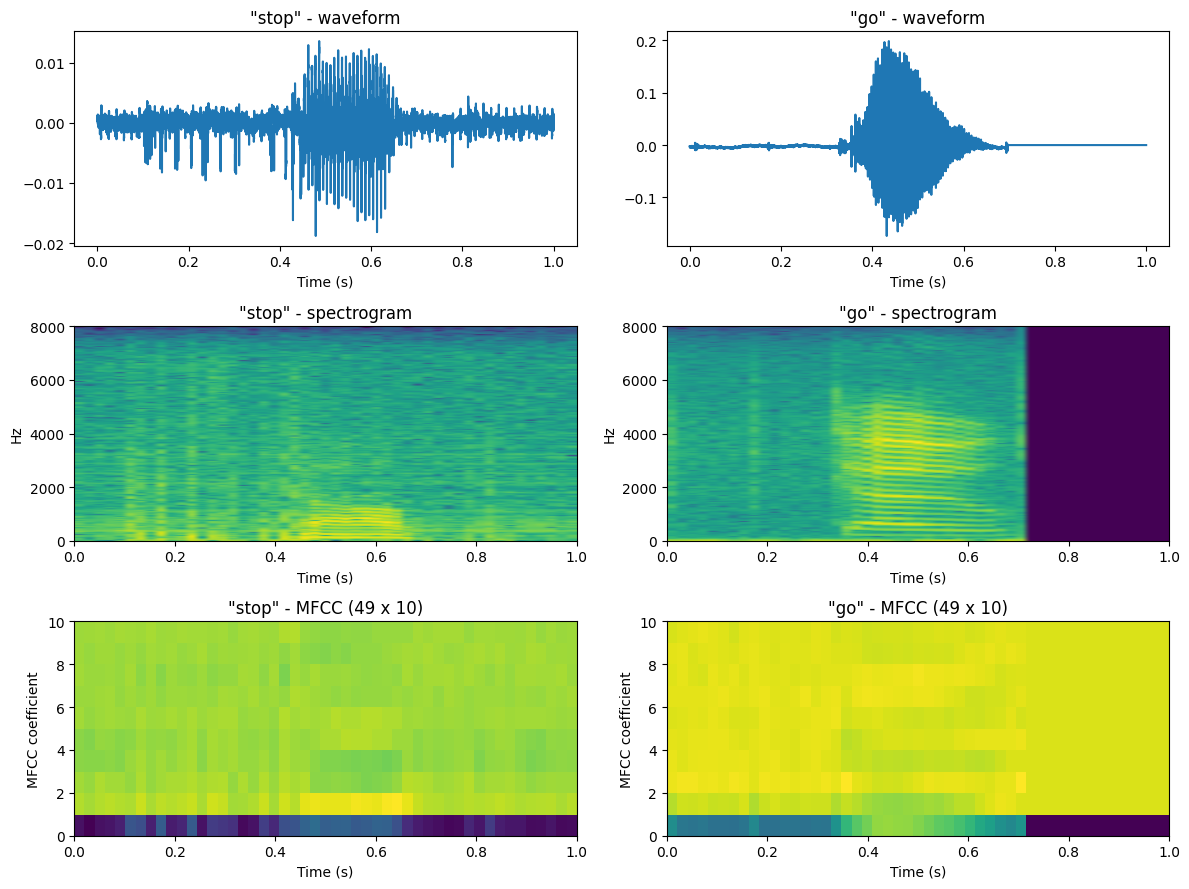

In [9]:
stop_clip = x_train[y_train == 0][0]
go_clip = load_wav(sorted((DATA_DIR / "go").glob("*.wav"))[0])

fig, axes = plt.subplots(3, 2, figsize=(12, 9))

for col, (name, clip) in enumerate([("stop", stop_clip), ("go", go_clip)]):
    t = np.arange(len(clip)) / SR
    axes[0, col].plot(t, clip)
    axes[0, col].set_title(f'"{name}" - waveform')
    axes[0, col].set_xlabel("Time (s)")

    spec = spectrogram(tf.constant(clip)).numpy()
    axes[1, col].imshow(np.log(spec.T + 1e-6), origin="lower", aspect="auto", extent=[0, 1, 0, SR / 2])
    axes[1, col].set_title(f'"{name}" - spectrogram')
    axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Hz")

    mfcc = waveform_to_mfcc(tf.constant(clip)).numpy()
    axes[2, col].imshow(mfcc.T, origin="lower", aspect="auto", extent=[0, 1, 0, NUM_MFCC])
    axes[2, col].set_title(f'"{name}" - MFCC (49 x 10)')
    axes[2, col].set_xlabel("Time (s)")
    axes[2, col].set_ylabel("MFCC coefficient")

plt.tight_layout()
plt.show()

Explanation for the manager (3 lines):
- The "stop" clip is quiet (amplitude about 0.01) with noise around it, and the word sits only between 0.4 s and 0.65 s, with its energy in the low coefficients and a few strong harmonics below 1 kHz
- The "go" clip is much louder (amplitude about 0.2), starts at 0.33 s and its harmonics reach up to 5 kHz. After 0.72 s the clip is zero padded, which shows as a flat MFCC block
- So the two MFCC pictures have a different energy pattern over time and over coefficients, and this pattern is what the model learns to separate. The "stop" clip looks darker only because it is quieter, the model sees normalised values

# 6 - Design the brain: DS-CNN

In [10]:
def build_ds_cnn(n_classes=3, filters=64, blocks=5):
    inp = keras.Input(shape=(49, 10, 1))

    x = keras.layers.Conv2D(filters, (10, 4), strides=(2, 2), padding="same", use_bias=False)(inp)
    x = keras.layers.BatchNormalization(momentum=0.9)(x)
    x = keras.layers.ReLU()(x)
    x = keras.layers.Dropout(0.2)(x)

    for _ in range(blocks):
        # depthwise separable block: depthwise 3x3 + pointwise 1x1
        x = keras.layers.DepthwiseConv2D((3, 3), padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization(momentum=0.9)(x)
        x = keras.layers.ReLU()(x)
        x = keras.layers.Conv2D(filters, (1, 1), use_bias=False)(x)
        x = keras.layers.BatchNormalization(momentum=0.9)(x)
        x = keras.layers.ReLU()(x)

    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.2)(x)
    out = keras.layers.Dense(n_classes, activation="softmax")(x)

    return keras.Model(inp, out, name="DS_CNN_KWS")

model = build_ds_cnn()
model.summary()

n_params = model.count_params()
print(f"Parameters           : {n_params:,}")
print(f"Float32 weights      : {n_params * 4 / 1024:.1f} KB")
print(f"int8 weights (approx): {n_params / 1024:.1f} KB")

Model: "DS_CNN_KWS"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 49, 10, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 25, 5, 64)         2560      
                                                                 
 batch_normalization (Batch  (None, 25, 5, 64)         256       
 Normalization)                                                  
                                                                 
 re_lu (ReLU)                (None, 25, 5, 64)         0         
                                                                 
 dropout (Dropout)           (None, 25, 5, 64)         0         
                                                                 
 depthwise_conv2d (Depthwis  (None, 25, 5, 64)         576       
 eConv2D)                                               

- DS-CNN replaces expensive 3x3 convolutions with a depthwise 3x3 plus a pointwise 1x1, which needs far fewer parameters, so it is a common choice for keyword spotting on microcontrollers
- First convolution (10 x 4, stride 2) reads the MFCC like an image, then 5 depthwise-separable blocks, global average pooling and a 3-class softmax
- The int8 weights are about one byte per parameter, so the model is expected to fit into the 100 KB limit. The real int8 .tflite size is measured in step 9
- Model has 28,931 parameters (27,523 trainable, the rest are batch norm statistics)
- As float32 the weights are 113 KB, which is above the limit, but as int8 they are about 28 KB, so it should fit under 100 KB. The measured .tflite size is in step 9
- Answer to "will it fit under 100 KB": yes, as an int8 model

# 7 - Teach it: training with augmentation

- **Time shift** (up to +/- 100 ms) for workers who speak early or late
- **Background noise** mixed in (80% of the clips, random volume) for a loud factory
- Augmentation is done on the fly on the waveform, so every epoch sees slightly different clips. Validation and test data are not augmented

In [11]:
SHIFT = int(0.1 * SR)
NOISE_N = 300

noise_bank = np.stack([make_noise_clip(np.random.default_rng(1000 + i)) for i in range(NOISE_N)])
noise_bank_tf = tf.constant(noise_bank)

MFCC_MEAN_TF = tf.constant(MFCC_MEAN)
MFCC_STD_TF = tf.constant(MFCC_STD)

def augment(wav):
    # random time shift, zero filled
    shift = tf.random.uniform([], -SHIFT, SHIFT + 1, dtype=tf.int32)
    padded = tf.pad(wav, [[SHIFT, SHIFT]])
    wav = tf.slice(padded, [SHIFT - shift], [SR])

    # random background noise
    noise = tf.gather(noise_bank_tf, tf.random.uniform([], 0, NOISE_N, dtype=tf.int32))
    gain = tf.random.uniform([], 0.0, 2.0) * tf.cast(tf.random.uniform([]) < 0.8, tf.float32)
    return tf.clip_by_value(wav + gain * noise, -1.0, 1.0)

def to_features(wav):
    m = (waveform_to_mfcc(wav) - MFCC_MEAN_TF) / MFCC_STD_TF
    return m[..., tf.newaxis]

BATCH = 64
train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(len(x_train), seed=SEED, reshuffle_each_iteration=True)
            .map(lambda w, l: (to_features(augment(w)), l), num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH)
            .prefetch(tf.data.AUTOTUNE))

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

history = model.fit(
    train_ds,
    validation_data=(x_val_f, y_val),
    epochs=40,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
37/37 [==============================] - 9s 42ms/step - loss: 0.8164 - accuracy: 0.6006 - val_loss: 1.8514 - val_accuracy: 0.3333 - lr: 0.0010
Epoch 2/40
37/37 [==============================] - 1s 30ms/step - loss: 0.4601 - accuracy: 0.8338 - val_loss: 0.2923 - val_accuracy: 0.8760 - lr: 0.0010
Epoch 3/40
37/37 [==============================] - 1s 31ms/step - loss: 0.3303 - accuracy: 0.8828 - val_loss: 0.2559 - val_accuracy: 0.8837 - lr: 0.0010
Epoch 4/40
37/37 [==============================] - 1s 30ms/step - loss: 0.2761 - accuracy: 0.9049 - val_loss: 0.2217 - val_accuracy: 0.9044 - lr: 0.0010
Epoch 5/40
37/37 [==============================] - 1s 30ms/step - loss: 0.2436 - accuracy: 0.9113 - val_loss: 0.1602 - val_accuracy: 0.9406 - lr: 0.0010
Epoch 6/40
37/37 [==============================] - 1s 30ms/step - loss: 0.2183 - accuracy: 0.9275 - val_loss: 0.1709 - val_accuracy: 0.9380 - lr: 0.0010
Epoch 7/40
37/37 [==============================] - 1s 31ms/step - loss: 0.2

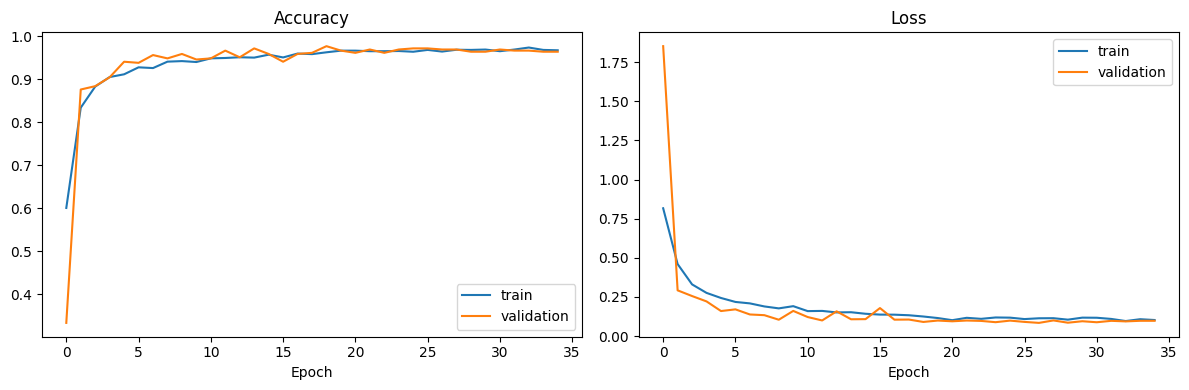

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

- Training stops by itself when the validation loss stops improving and the best weights are restored
- Training accuracy is measured on augmented clips, so it can sit below the validation accuracy
- Training ran for 35 epochs and stopped by itself, the best weights were restored
- Validation accuracy jumped from 33% in epoch 1 to about 88% in epoch 2 and then settled at 96% to 97%, validation loss fell from 1.85 to about 0.09
- Train and validation curves stay close to each other, so there is no sign of overfitting. Train accuracy is a little lower than validation because it is measured on augmented clips

# 8 - Safety check: evaluation on unseen speakers

In [14]:
probs = model.predict(x_test_f, verbose=0)
pred = probs.argmax(axis=1)

test_acc = float(np.mean(pred == y_test))
cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])

print(f"Test accuracy: {test_acc * 100:.2f}%")
print()
print(classification_report(y_test, pred, target_names=LABELS, digits=3))

Test accuracy: 99.25%

              precision    recall  f1-score   support

        stop      0.989     0.989     0.989        89
   _unknown_      0.989     0.989     0.989        89
   _silence_      1.000     1.000     1.000        89

    accuracy                          0.993       267
   macro avg      0.993     0.993     0.993       267
weighted avg      0.993     0.993     0.993       267



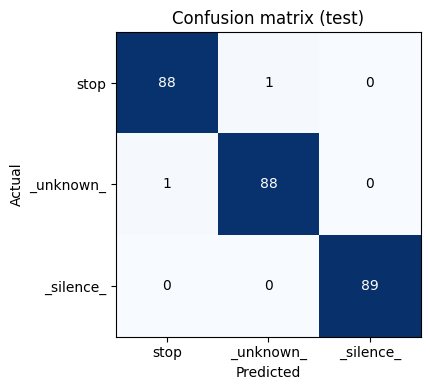

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix (test)")

for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

In [16]:
n_stop = int(cm[0].sum())
misses = int(cm[0, 1] + cm[0, 2])             # "stop" predicted as something else
false_alarms = int(cm[1, 0] + cm[2, 0])       # other words / silence predicted as "stop"

print(f"Misses       : {misses} of {n_stop} stop words not caught  (dangerous, belt keeps running)")
print(f"False alarms : {false_alarms} of {int(cm[1:].sum())} other clips wrongly called stop  (costly, line halts for nothing)")

Misses       : 1 of 89 stop words not caught  (dangerous, belt keeps running)
False alarms : 1 of 178 other clips wrongly called stop  (costly, line halts for nothing)


- Test set has only speakers that the model never saw in training
- Rows of the confusion matrix are the actual class, columns are the predicted class
- **Misses** = stop clips that were predicted as _unknown_ or _silence_, **false alarms** = _unknown_ or _silence_ clips predicted as stop. These are the two numbers for the safety officer
- Test accuracy on unseen speakers is 99.25% (265 of 267 clips correct). All three classes have F1 of 0.989 or higher, _silence_ is perfect
- Confusion matrix: 88 stop correct, 88 unknown correct, 89 silence correct, and only two mistakes
- **Misses: 1 of 89** stop words was not caught (it was called _unknown_)
- **False alarms: 1 of 178** other clips was wrongly called stop (an _unknown_ word)
- Accuracy is higher than the 85-95% that the lab expects. The _silence_ class is synthetic noise, which is easy, and the test set is clean dataset clips, so this number is optimistic. Lab 6 shows what happens with a real microphone

# 9 - Make it fit the chip: int8 TFLite

In [17]:
def get_file_size_kb(path):
    return os.path.getsize(path) / 1024

def evaluate_tflite(tflite_bytes, x, y):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    in_scale, in_zp = inp["quantization"]
    out_scale, out_zp = out["quantization"]

    correct = 0
    for i in range(len(x)):
        sample = x[i:i + 1]
        if inp["dtype"] == np.int8:
            sample = np.clip(np.round(sample / in_scale + in_zp), -128, 127).astype(np.int8)
        else:
            sample = sample.astype(np.float32)

        interpreter.set_tensor(inp["index"], sample)
        interpreter.invoke()
        p = interpreter.get_tensor(out["index"])

        if out["dtype"] == np.int8:
            p = (p.astype(np.float32) - out_zp) * out_scale

        correct += int(np.argmax(p) == y[i])

    return correct / len(x) * 100

In [18]:
# float32 TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float = converter.convert()
with open("kws_float.tflite", "wb") as f:
    f.write(tflite_float)

# full integer int8 TFLite
def representative_dataset():
    for i in range(300):
        yield [x_train_f[i:i + 1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_int8 = converter.convert()
with open("kws_int8.tflite", "wb") as f:
    f.write(tflite_int8)

float_kb = get_file_size_kb("kws_float.tflite")
int8_kb = get_file_size_kb("kws_int8.tflite")
keras_acc = test_acc * 100
float_acc = evaluate_tflite(tflite_float, x_test_f, y_test)
int8_acc = evaluate_tflite(tflite_int8, x_test_f, y_test)

results = pd.DataFrame({
    "Model": ["Keras float32", "TFLite float32", "TFLite int8"],
    "Size (KB)": [np.nan, float_kb, int8_kb],
    "Test accuracy (%)": [keras_acc, float_acc, int8_acc],
})
print(results.round(2).to_string(index=False))

print()
print(f"int8 accuracy loss vs TFLite float32: {float_acc - int8_acc:.2f} points")
print("Fits under 100 KB:", int8_kb < 100)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


         Model  Size (KB)  Test accuracy (%)
 Keras float32        NaN              99.25
TFLite float32     112.49              99.25
   TFLite int8      53.66              99.25

int8 accuracy loss vs TFLite float32: 0.00 points
Fits under 100 KB: True


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


- Weights go from 32 bit to 8 bit, and the representative dataset (300 training MFCCs) lets the converter choose the scale of every activation
- Input and output are int8, so the whole graph is integer, which is what the microcontroller needs
- Size and accuracy of float32 and int8 are compared, with the 100 KB limit and the 1% accuracy loss target from the lab
- int8 model is 53.66 KB against 112.49 KB for float32, which is 2.1x smaller and under the 100 KB limit. It is slightly above the 45-50 KB that the lab mentions
- Test accuracy is 99.25% for Keras, TFLite float32 and TFLite int8, so the accuracy loss from quantization is 0.00 points (limit is 1%)
- The representative dataset of 300 MFCCs was enough to choose the int8 scales for this model

## Export for Lab 6

In [19]:
interpreter = tf.lite.Interpreter(model_content=tflite_int8)
interpreter.allocate_tensors()
in_scale, in_zp = interpreter.get_input_details()[0]["quantization"]

config = {
    "sample_rate": SR,
    "clip_samples": SR,
    "window_ms": 30,
    "hop_ms": 20,
    "frame_length": FRAME_LEN,
    "frame_step": FRAME_STEP,
    "fft_length": FFT_LEN,
    "num_mel_bins": NUM_MEL,
    "lower_edge_hz": FMIN,
    "upper_edge_hz": FMAX,
    "num_mfcc": NUM_MFCC,
    "mfcc_shape": [49, 10],
    "mfcc_mean": MFCC_MEAN.tolist(),
    "mfcc_std": MFCC_STD.tolist(),
    "labels": LABELS,
    "input_scale": float(in_scale),
    "input_zero_point": int(in_zp),
    "lab5_test_accuracy_int8": round(int8_acc, 2),
}

with open("kws_config.json", "w") as f:
    json.dump(config, f, indent=2)

# unseen test clips (speakers the model never heard) for the Lab 6 bench test and the simulated work shift
pick = {k: np.where(y_test == k)[0][:n] for k, n in [(0, 20), (1, 30), (2, 10)]}
idx = np.concatenate([pick[0], pick[1], pick[2]])
np.savez("kws_bench_clips.npz", audio=x_test[idx], labels=y_test[idx], names=n_test[idx])

print(json.dumps({k: v for k, v in config.items() if k not in ("mfcc_mean", "mfcc_std")}, indent=2))
print("Saved: kws_int8.tflite, kws_float.tflite, kws_config.json, kws_bench_clips.npz")

{
  "sample_rate": 16000,
  "clip_samples": 16000,
  "window_ms": 30,
  "hop_ms": 20,
  "frame_length": 480,
  "frame_step": 320,
  "fft_length": 512,
  "num_mel_bins": 40,
  "lower_edge_hz": 20.0,
  "upper_edge_hz": 4000.0,
  "num_mfcc": 10,
  "mfcc_shape": [
    49,
    10
  ],
  "labels": [
    "stop",
    "_unknown_",
    "_silence_"
  ],
  "input_scale": 0.057296961545944214,
  "input_zero_point": 3,
  "lab5_test_accuracy_int8": 99.25
}
Saved: kws_int8.tflite, kws_float.tflite, kws_config.json, kws_bench_clips.npz


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [20]:
# download the files so that they can be used in Lab 6 (Colab only)
try:
    from google.colab import files
    for f in ["kws_int8.tflite", "kws_config.json", "kws_bench_clips.npz"]:
        files.download(f)
except ImportError:
    print("Not running in Colab, files are in the current folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

- kws_int8.tflite is the model for the chip, kws_config.json stores the MFCC settings, the normalisation numbers and the input scale so that Lab 6 uses exactly the same front-end
- kws_bench_clips.npz has unseen test clips (20 stop, 30 unknown, 10 silence) that Lab 6 uses for the bench test and for a simulated work shift
- Config has the input scale 0.0573 and zero point 3, the same MFCC settings (30 ms window, 20 ms hop, 49 x 10) and the training mean and std, so Lab 6 uses the same front-end

# 10 - Report

- Dataset: 3 balanced classes (stop, _unknown_, _silence_), 2,346 train, 387 validation and 267 test clips, split by speaker (819 / 128 / 103 speakers)
- Features: 30 ms window, 20 ms hop, 49 x 10 MFCC. "stop" and "go" show a different energy pattern over time
- Model: DS-CNN with 28,931 parameters, trained with time shift and background noise augmentation for 35 epochs
- Result: 99.25% test accuracy on unseen speakers, 1 miss out of 89 stop words and 1 false alarm out of 178 other clips
- Deployment: int8 model of 53.66 KB (fits the 100 KB limit) with 0.00 points accuracy loss versus float32
- Caution: the _silence_ class is synthetic and the test clips are clean, so the real microphone results in Lab 6 are expected to be lower